# АБПВ трамвая: EDA, feature engineering, прогноз торможения по препятствию

**Цель.** Разобрать телеметрию системы помощи водителю трамвая (АБПВ), построить объяснимые признаки
на двух уровнях (момент времени и эпизод срабатывания) и показать их пользу на задаче:
*будет ли в ближайшие 10 с применено торможение по препятствию* (`danger_real` перейдёт в 1).

**Данные.** 15 поездок (`trips/*.parquet`, единая таблица CSV+JSON, шаг около 5 с, у событий 0-2 с)
и 13 357 эпизодов срабатываний (`episodes.json`, детектор `backend/events.py`).

**Что получится в конце.**
1. EDA: срабатывания по типам, часам, вагонам, маршрутам; доля управления ассистентом; качество данных.
2. Таблица признаков (имя, формула, смысл, поле-источник) для двух уровней.
3. Модель LightGBM (или HistGradientBoosting) против правила и логрегрессии, сплит по вагонам, PR-AUC, recall@precision, permutation importance, разбор ошибок.
4. Кластеры эпизодов с интерпретацией.
5. Файлы в `out/`: `row_features.parquet`, `episode_features.parquet`, `feature_table.csv`, `feature_importance.csv`, `metrics.json`.

## 0. Зависимости
В Colab всё есть (pandas, pyarrow, scikit-learn, lightgbm, matplotlib). Ячейка ставит только недостающее.

In [1]:
import os, importlib, subprocess, sys
# OpenBLAS резервирует буфер на каждый поток (сотни МБ на 8 ядрах): ограничиваем до импорта numpy
for _v in ["OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(_v, "2")
for pkg in ["pyarrow", "lightgbm"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

## 1. Настройки, сиды, версии
`FAST=True` урезает permutation importance и подбор k, если мало памяти или времени.

In [2]:
import os, sys, json, zipfile, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
FAST = False
IN_COLAB = "google.colab" in sys.modules
HORIZON_S = 10      # горизонт прогноза, с
GRID_S = 5          # шаг регулярной сетки, с
MAX_SPEED = 100.0   # км/ч: выше считаем мусором датчика

try:
    import lightgbm as lgb
    HAS_LGB = True
except Exception:
    HAS_LGB = False

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__ if HAS_LGB else "нет",
      "| matplotlib", matplotlib.__version__, "| IN_COLAB", IN_COLAB)

python 3.12.7 | pandas 3.0.6 | numpy 2.5.3 | sklearn 1.9.1 | lightgbm 4.7.0 | matplotlib 3.11.2 | IN_COLAB False


## 2. Загрузка данных
* **Colab:** архив `data_for_colab.zip` берётся с Google Drive (`/content/drive/MyDrive/get_tram/data_for_colab.zip`),
  если его там нет, появится кнопка `files.upload()`.
* **Локально:** рядом лежащий `data_for_colab.zip` (распаковывается в `notebooks/data_colab/`), если его нет, то `../data/processed`.

Parquet читаем только нужными колонками, по одной поездке, числа приводим к `float32`, строки к `category`.

In [3]:
if IN_COLAB:
    DATA = Path("/content/data")
    if not (DATA / "episodes.json").exists():
        zp = Path("/content/drive/MyDrive/get_tram/data_for_colab.zip")
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive не подключён:", e)
        if not zp.exists():
            from google.colab import files
            up = files.upload()               # выберите data_for_colab.zip
            zp = Path("/content") / next(iter(up))
        zipfile.ZipFile(zp).extractall(DATA)
    OUT = Path("/content/out")
else:
    # локально берём тот же архив, что и в Colab (меньше колонок, episodes без facts), иначе ../data/processed
    if Path("data_for_colab.zip").exists():
        DATA = Path("data_colab")
        if not (DATA / "episodes.json").exists():
            zipfile.ZipFile("data_for_colab.zip").extractall(DATA)
    else:
        DATA = Path("../data/processed")
    OUT = Path("out")
OUT.mkdir(parents=True, exist_ok=True)
TRIP_FILES = sorted((DATA / "trips").glob("*.parquet"))
print(DATA.resolve(), "| поездок:", len(TRIP_FILES))

D:\ЦУ\3 курс\hackathons\get_tram\notebooks\data_colab | поездок: 15


In [4]:
import gc
import pyarrow as pa
import pyarrow.parquet as pq
pa.set_memory_pool(pa.system_memory_pool())   # системный аллокатор: память возвращается ОС после каждой поездки

COLS = ["t", "trip", "wagon", "route", "speed", "goal_speed", "goal_obj_type", "m_warn_level",
        "controller", "handle_driver", "handle_assistant",
        "brake_mech", "brake_rail", "brake_crash", "brake_emergency", "as_is_skid",
        "danger_act", "danger_real", "danger_work", "tl_act", "tl_real", "tl_work",
        "sl_act", "sl_real", "sl_work", "adas_on", "stop_name", "dist_to_stop", "lat", "lon",
        "fsm_state", "m_speed_mode", "probability", "loc_converged", "is_safety_pedal_turned_on_fb",
        "m_danger_obj_status",
        "ubloxGps", "t25Front", "leftImage", "tramSlaveVisor", "minsEth", "odoFbTram", "dbwFbTram"]
SENSORS = ["ubloxGps", "t25Front", "leftImage", "tramSlaveVisor", "minsEth", "odoFbTram", "dbwFbTram"]
CAT_COLS = ["trip", "wagon", "goal_obj_type", "controller", "stop_name", "fsm_state", "m_danger_obj_status"]

def read_trip(path, cols=None):
    cols = cols or COLS
    have = pq.ParquetFile(path).schema_arrow.names
    df = pq.read_table(path, columns=[c for c in cols if c in have]).to_pandas()
    for c in cols:
        if c not in df:
            df[c] = np.nan
    df["t"] = df["t"].astype("datetime64[ns, Europe/Moscow]")
    for c in df.columns:
        if c == "t":
            continue
        if c in CAT_COLS:
            df[c] = df[c].astype(str).replace({"None": np.nan, "nan": np.nan}).astype("category")
        else:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float32")
    if "route" in df:
        df["route"] = df["route"].round(2)
    return df.sort_values("t", kind="stable").reset_index(drop=True)

raw_info = []
for p in TRIP_FILES:
    d = read_trip(p, ["t", "wagon", "speed", "controller", "danger_real"])
    dt = d["t"].diff().dt.total_seconds()
    raw_info.append(dict(trip=p.stem, wagon=str(d["wagon"].iloc[0]), rows=len(d),
                         start=d["t"].iloc[0], end=d["t"].iloc[-1],
                         dt_median=dt.median(), share_dt_le2=(dt <= 2).mean(), share_dt_5=((dt > 4) & (dt <= 6)).mean(),
                         gaps_gt60=(dt > 60).sum(), speed_out=(d["speed"] > MAX_SPEED).sum(),
                         speed_na=d["speed"].isna().sum(),
                         auto_share=(d["controller"] == "auto").mean(),
                         danger_onsets=int(((d["danger_real"] > .5) & ~(d["danger_real"].shift(fill_value=0) > .5)).sum())))
raw_info = pd.DataFrame(raw_info); del d; gc.collect()
print("всего строк:", raw_info.rows.sum())
raw_info

всего строк: 510118


,trip,wagon,rows,start,end,dt_median,share_dt_le2,share_dt_5,gaps_gt60,speed_out,speed_na,auto_share,danger_onsets
0,0210_03_10,0210,23947,2026-10-03 06:00:17+03:00,2026-10-03 21:35:50+03:00,1.0,0.613689,0.258446,1,41,0,0.411576,109
1,3119_01_10__07_10,3119,81165,2026-10-01 09:36:28+03:00,2026-10-06 00:36:18+03:00,3.0,0.472741,0.385375,69,29,0,0.257044,770
2,3139_14_09,3139,28777,2026-09-14 04:23:15+03:00,2026-09-15 00:23:35+03:00,1.0,0.585711,0.294437,0,1,0,0.343573,324
3,3139_16_09,3139,19829,2026-09-16 05:14:32+03:00,2026-09-16 22:13:37+03:00,4.0,0.463614,0.411569,0,0,0,0.260074,356
4,3139_17_09,3139,22776,2026-09-17 05:07:16+03:00,2026-09-18 01:57:22+03:00,2.0,0.502590,0.379127,3,1,0,0.197445,358
5,3139_20_09,3139,23813,2026-09-20 04:56:39+03:00,2026-09-21 01:02:15+03:00,3.0,0.488053,0.385630,2,8,0,0.202662,190
6,7752_15_09__22_09,7752,105988,2026-09-15 04:36:39+03:00,2026-09-21 12:44:36+03:00,5.0,0.423944,0.517191,16,970,0,0.209552,1039
7,7752_23_09__29_09,7752,58990,2026-09-23 18:33:04+03:00,2026-09-29 00:56:03+03:00,5.0,0.351534,0.591015,8,521,0,0.128276,208
8,7821_21_09,7821,15576,2026-09-21 04:38:12+03:00,2026-09-22 00:44:28+03:00,5.0,0.297316,0.661787,2,159,0,0.198382,84
9,7821_22_09,7821,12511,2026-09-22 05:20:46+03:00,2026-09-22 22:44:18+03:00,5.0,0.173288,0.777396,1,57,0,0.117017,25


## 3. EDA
### 3.1 Качество данных
Шаг записи, разрывы, выбросы скорости, пропуски. Пропуски считаем на одной типичной поездке и по всем (по колонкам).

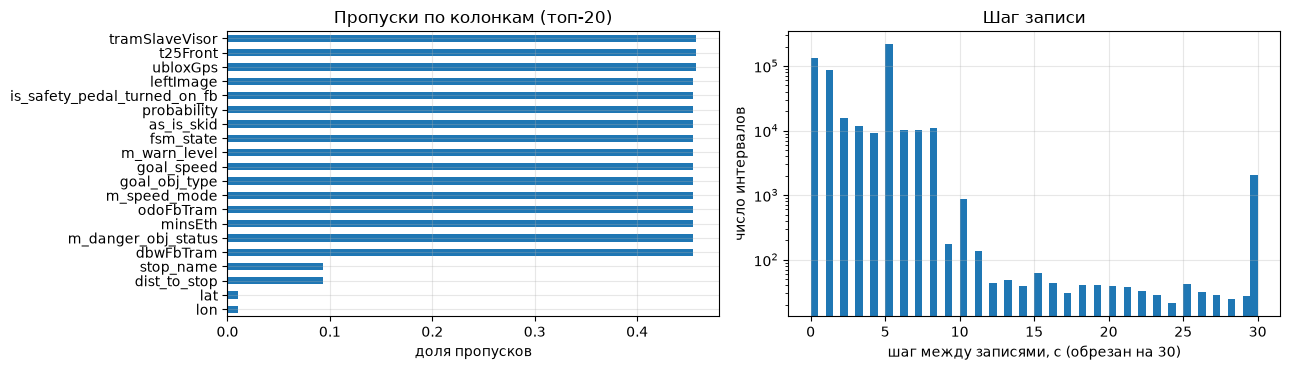

шаг <=2 с: 46.6%, около 5 с: 44.5%, >=30 с: 0.40%
выбросов скорости >100 км/ч: 2585 | пропусков скорости: 0


In [5]:
na_parts, dts = [], []
for p in TRIP_FILES:
    d = read_trip(p)
    na_parts.append(d.isna().sum())
    dts.append(d["t"].diff().dt.total_seconds().dropna().clip(upper=30).astype("float32").values)
del d; gc.collect()
na = (sum(na_parts) / raw_info.rows.sum()).sort_values(ascending=False)
dts = np.concatenate(dts)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
na[na > 0].head(20).plot.barh(ax=ax[0]); ax[0].set_xlabel("доля пропусков"); ax[0].set_title("Пропуски по колонкам (топ-20)")
ax[0].invert_yaxis()
ax[1].hist(dts, bins=60); ax[1].set_yscale("log"); ax[1].set_xlabel("шаг между записями, с (обрезан на 30)")
ax[1].set_ylabel("число интервалов"); ax[1].set_title("Шаг записи")
plt.tight_layout(); plt.show()
print(f"шаг <=2 с: {(dts<=2).mean():.1%}, около 5 с: {((dts>4)&(dts<=6)).mean():.1%}, >=30 с: {(dts>=30).mean():.2%}")
print("выбросов скорости >100 км/ч:", int(raw_info.speed_out.sum()), "| пропусков скорости:", int(raw_info.speed_na.sum()))

**Вывод.** Основной шаг 5 с, но заметная часть интервалов 0-2 с: это сгущение записей вокруг событий.
Плотность записи зависит от событий (в том числе будущих), поэтому для модели все признаки строятся
на **регулярной 5-секундной сетке** (значение на момент сетки = последняя запись не позже него).
Так частота строк не становится скрытой подсказкой о предстоящем срабатывании.

### 3.2 Эпизоды: типы, часы, вагоны, маршруты, управление

(13357, 27)


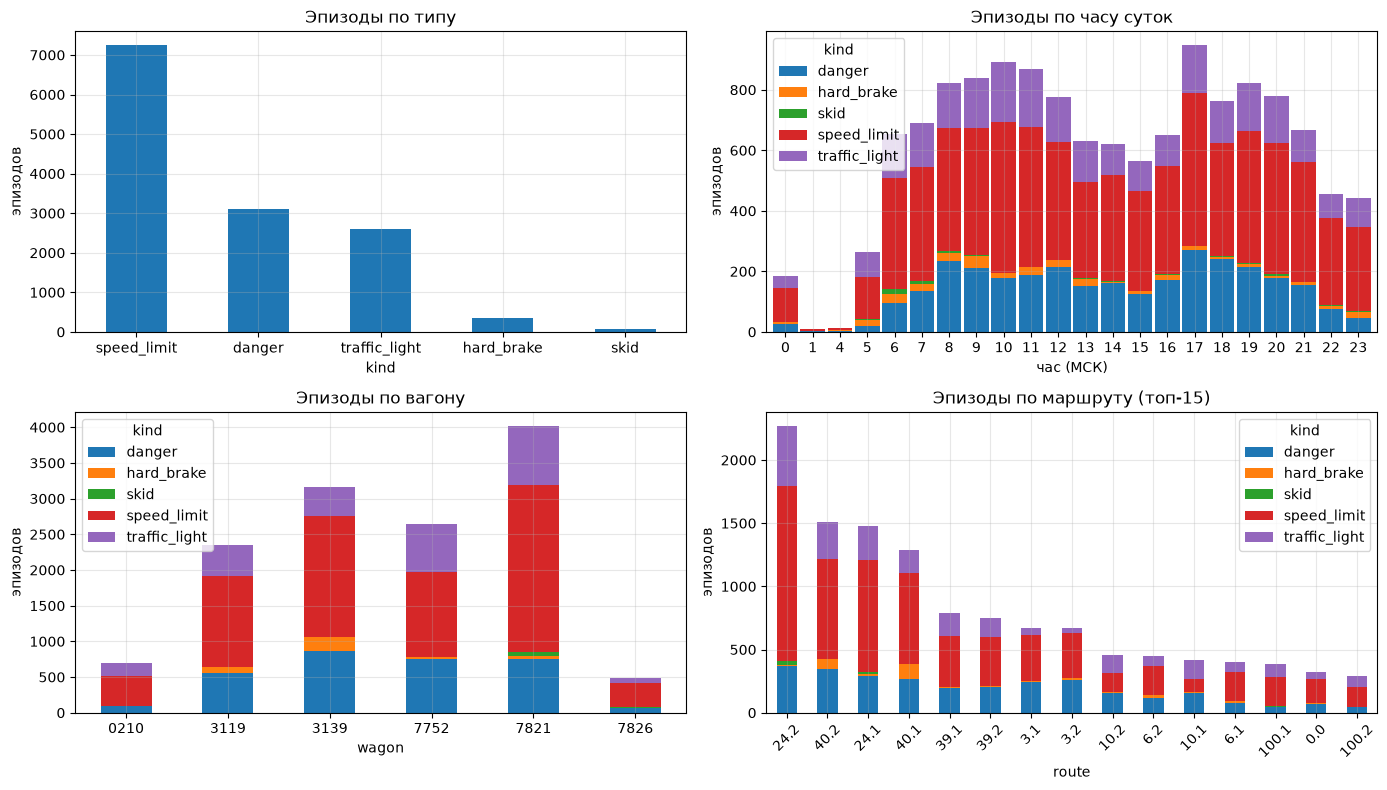

In [6]:
with open(DATA / "episodes.json", encoding="utf-8") as f:
    _raw = json.load(f)
for e in _raw:
    e.pop("facts", None)            # тексты фактов для модели не нужны, а памяти занимают много
eps = pd.DataFrame(_raw); del _raw; gc.collect()
eps["route"] = eps["route"].astype(str); eps["wagon"] = eps["wagon"].astype(str)
for c in ["start", "end", "win_start", "win_end"]:
    eps[c] = pd.to_datetime(eps[c], utc=True).dt.tz_convert("Europe/Moscow")
eps["hour"] = eps["start"].dt.hour
print(eps.shape)
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
eps.kind.value_counts().plot.bar(ax=ax[0, 0], rot=0); ax[0, 0].set_title("Эпизоды по типу"); ax[0, 0].set_ylabel("эпизодов")
pd.crosstab(eps.hour, eps.kind).plot.bar(stacked=True, ax=ax[0, 1], rot=0, width=.9)
ax[0, 1].set_title("Эпизоды по часу суток"); ax[0, 1].set_xlabel("час (МСК)"); ax[0, 1].set_ylabel("эпизодов")
pd.crosstab(eps.wagon, eps.kind).plot.bar(stacked=True, ax=ax[1, 0], rot=0); ax[1, 0].set_title("Эпизоды по вагону"); ax[1, 0].set_ylabel("эпизодов")
top_r = eps.route.value_counts().head(15).index
pd.crosstab(eps[eps.route.isin(top_r)].route, eps.kind).loc[top_r].plot.bar(stacked=True, ax=ax[1, 1], rot=45)
ax[1, 1].set_title("Эпизоды по маршруту (топ-15)"); ax[1, 1].set_ylabel("эпизодов")
plt.tight_layout(); plt.show()

In [7]:
# Нормировка на время в пути: эпизоды на час записи по вагону
hours = raw_info.groupby("wagon").apply(lambda g: ((g.end - g.start).dt.total_seconds()).sum() / 3600)
rate = (pd.crosstab(eps.wagon, eps.kind).div(hours, axis=0)).round(1)
rate["часов записи (с разрывами)"] = hours.round(1)
print("Эпизодов в час записи по вагонам:"); display(rate)
print("Тяжесть по типу эпизода (доли):")
display(pd.crosstab(eps.kind, eps.severity, normalize="index").round(2))
print("Управление в момент эпизода (доли):")
display(pd.crosstab(eps.kind, eps.controller, normalize="index").round(2))
print("Тип объекта для эпизодов 'danger':"); display(eps[eps.kind == "danger"].obj_type.value_counts())

Эпизодов в час записи по вагонам:


kind,danger,hard_brake,skid,speed_limit,traffic_light,часов записи (с разрывами)
wagon,,,,,,
0210,5.7,0.0,0.6,26.4,11.9,15.6
3119,5.1,0.8,0.0,11.4,4.0,111.0
3139,11.1,2.5,0.1,21.7,5.1,77.9
7752,2.7,0.1,0.0,4.3,2.4,278.5
7821,2.2,0.1,0.1,6.8,2.4,343.3
7826,3.4,0.0,0.1,16.2,3.6,21.0


Тяжесть по типу эпизода (доли):


severity,0,1,2,3
kind,,,,
danger,0.0,0.00,0.99,0.01
hard_brake,0.0,0.00,0.27,0.73
skid,0.0,0.00,1.00,0.00
speed_limit,1.0,0.00,0.00,0.00
traffic_light,0.0,0.97,0.01,0.02


Управление в момент эпизода (доли):


controller,auto,driver,und
kind,,,
danger,0.36,0.57,0.07
hard_brake,0.14,0.80,0.06
skid,0.10,0.76,0.14
speed_limit,0.62,0.07,0.32
traffic_light,0.54,0.38,0.08


Тип объекта для эпизодов 'danger':


obj_type
Unknown               2485
Vehicle                379
Ped                    127
TrafficLightSignal      67
Tram                    41
Name: count, dtype: int64

Доля времени по источнику управления, всего:


,sec,sec_moving
controller,,
auto,0.119,0.243
driver,0.823,0.692
und,0.058,0.066


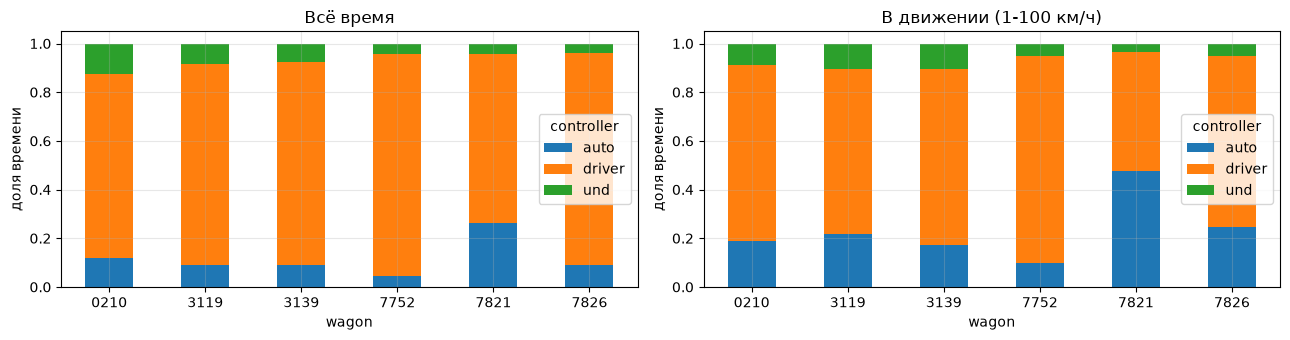

In [8]:
# Доля времени под управлением ассистента: по строкам с весом шага (dt, обрезан 30 с)
rows = []
for p in TRIP_FILES:
    d = read_trip(p, ["t", "wagon", "controller", "speed"])
    w = d["t"].diff().shift(-1).dt.total_seconds().clip(0, 30).fillna(0)
    moving = d["speed"].between(1, MAX_SPEED)
    for c in ["auto", "driver", "und"]:
        rows.append(dict(trip=p.stem, wagon=str(d.wagon.iloc[0]), controller=c,
                         sec=float(w[d.controller == c].sum()), sec_moving=float(w[(d.controller == c) & moving].sum())))
ctl = pd.DataFrame(rows); del d; gc.collect()
share = ctl.pivot_table(index="wagon", columns="controller", values="sec", aggfunc="sum")
share = share.div(share.sum(1), axis=0)
share_mv = ctl.pivot_table(index="wagon", columns="controller", values="sec_moving", aggfunc="sum")
share_mv = share_mv.div(share_mv.sum(1), axis=0)
tot = ctl.groupby("controller")[["sec", "sec_moving"]].sum(); tot = tot / tot.sum()
print("Доля времени по источнику управления, всего:"); display(tot.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
share.plot.bar(stacked=True, ax=ax[0], rot=0); ax[0].set_title("Всё время"); ax[0].set_ylabel("доля времени")
share_mv.plot.bar(stacked=True, ax=ax[1], rot=0); ax[1].set_title("В движении (1-100 км/ч)"); ax[1].set_ylabel("доля времени")
plt.tight_layout(); plt.show()

## 4. Feature engineering, уровень 1: признаки момента времени (только прошлое)

Для каждой поездки строим регулярную сетку с шагом 5 с. Значения полей берутся из последней записи
не позже момента сетки (`merge_asof backward`, допуск 30 с; внутри больших разрывов точек нет).
Скользящие окна (`rolling('15s')`) смотрят только назад, включая текущий момент.
Времена событий (`since_*`, `n_*_10min`) считаются по исходным записям, тоже только до текущего момента.
Скорость выше 100 км/ч заменяется пропуском и заполняется предыдущим значением.

**Целевая переменная:** `y = 1`, если в интервал (t, t+10 с] попадает начало нового эпизода торможения по препятствию.
Эпизод: фронты `danger_real` 0→1 в исходных записях, склеенные при паузе меньше 8 с (как в `backend/events.py`),
иначе повторные «дребезжащие» включения внутри одного торможения тривиально предсказываются по `since_danger`.
Обучаем только на моментах, когда подсистема обнаружения препятствий работает (`danger_work == 1`),
и вне идущего эпизода (`danger_real` не включался последние 8 с). Иначе модель первым делом учит очевидное
«подсистема выключена, значит торможения не будет». Поле `danger_act` в признаки не берём: оно почти совпадает с `danger_real`.

In [9]:
OBJ = ["Ped", "Vehicle", "Tram", "TrafficLightSignal"]
FSM = ["Moving", "Yield", "Warn_Moving", "Start_Moving", "Stop", "Stopped"]
CAP = 3600.0  # с: потолок для "времени с последнего"

def onsets_t(t, flag):
    f = (flag.fillna(0) > .5).values
    prev = np.r_[False, f[:-1]]
    return t.values[f & ~prev]

def since(grid_t, ev_t):
    # секунды с последнего события (время события <= t); CAP если не было
    g = grid_t.values.astype("datetime64[ns]").astype("int64"); e = np.asarray(ev_t).astype("datetime64[ns]").astype("int64")
    i = np.searchsorted(e, g, side="right") - 1
    out = np.full(len(g), CAP, dtype="float32")
    ok = i >= 0
    out[ok] = np.minimum((g[ok] - e[i[ok]]) / 1e9, CAP)
    return out

def count_past(grid_t, ev_t, window_s):
    g = grid_t.values.astype("datetime64[ns]").astype("int64"); e = np.asarray(ev_t).astype("datetime64[ns]").astype("int64")
    return (np.searchsorted(e, g, side="right") - np.searchsorted(e, g - int(window_s * 1e9), side="right")).astype("float32")

def time_to_next(grid_t, ev_t):
    g = grid_t.values.astype("datetime64[ns]").astype("int64"); e = np.asarray(ev_t).astype("datetime64[ns]").astype("int64")
    i = np.searchsorted(e, g, side="right")
    out = np.full(len(g), np.inf)
    ok = i < len(e)
    out[ok] = (e[i[ok]] - g[ok]) / 1e9
    return out

def trip_features(path):
    r = read_trip(path)
    r.loc[r["speed"] > MAX_SPEED, "speed"] = np.nan
    r["speed"] = r["speed"].ffill()
    ev = {k: onsets_t(r["t"], r[k]) for k in ["danger_real", "tl_real", "sl_real", "brake_mech", "brake_rail", "as_is_skid"]}
    ev["warn"] = onsets_t(r["t"], r["m_warn_level"] > 0)
    ctrl_codes = r["controller"].astype(str)
    ev["ctrl_switch"] = r["t"].values[(ctrl_codes != ctrl_codes.shift()).values & (np.arange(len(r)) > 0)]

    gt = pd.date_range(r["t"].iloc[0].ceil(f"{GRID_S}s"), r["t"].iloc[-1], freq=f"{GRID_S}s")
    # точки сетки только там, где последняя запись не старше 30 с (без длинных разрывов: ночь, стоянка в парке)
    rt = r["t"].values.astype("datetime64[ns]").astype("int64"); gv = gt.values.astype("datetime64[ns]").astype("int64")
    j = np.searchsorted(rt, gv, side="right") - 1
    grid = pd.DataFrame({"t": gt[(j >= 0) & (gv - rt[np.maximum(j, 0)] <= 30e9)]})
    g = pd.merge_asof(grid, r, on="t", direction="backward", tolerance=pd.Timedelta("30s"))
    g = g[g["speed"].notna()].reset_index(drop=True)
    gi = g.set_index("t")
    # непрерывные куски сетки (разрыв > шага) нужны для корректных разностей
    seg = (g["t"].diff().dt.total_seconds() != GRID_S).cumsum()

    F = pd.DataFrame(index=g.index)
    F["speed"] = g["speed"]
    dv = g.groupby(seg)["speed"].diff()
    F["accel"] = (dv / 3.6 / GRID_S).astype("float32")                  # м/с^2
    F["jerk"] = (F.groupby(seg)["accel"].diff() / GRID_S).astype("float32")
    for w in [5, 15, 30]:
        roll = gi["speed"].rolling(f"{w}s")
        F[f"speed_mean_{w}s"] = roll.mean().values
        if w > 5:
            F[f"speed_std_{w}s"] = roll.std().values
            F[f"speed_drop_{w}s"] = (roll.max() - gi["speed"]).values
    acc = pd.Series(F["accel"].values, index=gi.index)
    F["accel_min_15s"] = acc.rolling("15s").min().values
    F["accel_mean_30s"] = acc.rolling("30s").mean().values
    F["goal_speed"] = g["goal_speed"]
    F["overspeed"] = g["speed"] - g["goal_speed"]
    F["overspeed_pos"] = F["overspeed"].clip(lower=0)
    F["warn_level"] = g["m_warn_level"]
    F["warn_max_15s"] = gi["m_warn_level"].rolling("15s").max().values
    F["warn_delta"] = g.groupby(seg)["m_warn_level"].diff()
    ot = g["goal_obj_type"].astype(str)
    for o in OBJ:
        F[f"obj_{o}"] = (ot == o).astype("float32")
    F["obj_na"] = g["goal_obj_type"].isna().astype("float32")
    for k, name in [("danger_real", "danger"), ("tl_real", "tl"), ("sl_real", "sl"), ("brake_mech", "brake_mech"),
                    ("brake_rail", "brake_rail"), ("warn", "warn")]:
        F[f"since_{name}"] = since(g["t"], ev[k])
    for k, name in [("danger_real", "danger"), ("tl_real", "tl"), ("sl_real", "sl"), ("brake_mech", "brake_mech"), ("warn", "warn")]:
        F[f"n_{name}_10min"] = count_past(g["t"], ev[k], 600)
    c = g["controller"].astype(str)
    F["ctrl_auto"] = (c == "auto").astype("float32")
    F["ctrl_und"] = (c == "und").astype("float32")
    F["since_ctrl_switch"] = since(g["t"], ev["ctrl_switch"])
    F["n_ctrl_switch_5min"] = count_past(g["t"], ev["ctrl_switch"], 300)
    F["auto_share_5min"] = pd.Series(F["ctrl_auto"].values, index=gi.index).rolling("300s").mean().values
    F["handle_driver"] = g["handle_driver"]
    F["handle_assistant"] = g["handle_assistant"]
    F["handle_diff"] = g["handle_assistant"] - g["handle_driver"]
    F["brake_mech"] = g["brake_mech"]
    F["brake_mech_share_30s"] = gi["brake_mech"].rolling("30s").mean().values
    F["dist_to_stop"] = g["dist_to_stop"]
    F["near_stop_50m"] = (g["dist_to_stop"] < 50).astype("float32")
    h = g["t"].dt.hour + g["t"].dt.minute / 60
    F["hour"] = h.astype("float32")
    F["hour_sin"] = np.sin(2 * np.pi * h / 24).astype("float32")
    F["hour_cos"] = np.cos(2 * np.pi * h / 24).astype("float32")
    for k in ["danger_work", "tl_work", "sl_work", "adas_on", "m_speed_mode", "loc_converged", "is_safety_pedal_turned_on_fb", "probability"]:
        F[k] = g[k]
    F["danger_status_ok"] = (g["m_danger_obj_status"].astype(str) == "ProperlyWork").astype("float32")
    fs = g["fsm_state"].astype(str)
    for s in ["Yield", "Warn_Moving", "Start_Moving", "Moving"]:
        F[f"fsm_{s}"] = (fs == s).astype("float32")
    F["sensors_ok"] = g[SENSORS].fillna(0).sum(1)
    F["sensors_missing"] = (len(SENSORS) - F["sensors_ok"]).astype("float32")
    F["gps_ok"] = g["ubloxGps"]
    F = F.astype("float32")

    meta = g[["t", "trip", "wagon", "route", "controller", "lat", "lon", "stop_name"]].copy()
    meta["trip"] = path.stem; meta["wagon"] = str(r["wagon"].dropna().iloc[0])
    # эпизод торможения по препятствию: фронты danger_real ближе 8 с друг к другу склеиваем (как в backend/events.py)
    act = r["t"].values[(r["danger_real"].fillna(0) > .5).values]
    ep_on = act[np.r_[True, np.diff(act) > np.timedelta64(8, "s")]] if len(act) else act
    meta["danger_now"] = (since(g["t"], act) < 8) | (g["danger_real"].fillna(0) > .5).values   # внутри идущего эпизода
    meta["tt_next_danger"] = time_to_next(g["t"], ep_on).astype("float32")
    meta["y"] = (meta["tt_next_danger"] <= HORIZON_S).astype("int8")
    out = pd.concat([meta, F], axis=1)
    del r, g, gi, F
    return out

t0 = time.time()
parts = []
for p in TRIP_FILES:
    parts.append(trip_features(p)); gc.collect()
X_all = pd.concat(parts, ignore_index=True); del parts
for c in ["trip", "wagon", "controller", "stop_name"]:
    X_all[c] = X_all[c].astype(str).astype("category")
FEATS = [c for c in X_all.columns if c not in ["t", "trip", "wagon", "route", "controller", "lat", "lon", "stop_name",
                                                "danger_now", "tt_next_danger", "y"]]
print(f"{time.time()-t0:.0f} с | строк сетки: {len(X_all):,} | признаков: {len(FEATS)} | память: {X_all.memory_usage(deep=True).sum()/2**20:.0f} МБ")
print("доля y=1 вне эпизодов:", round(X_all.loc[~X_all.danger_now, "y"].mean(), 4))

6 с | строк сетки: 316,588 | признаков: 65 | память: 88 МБ
доля y=1 вне эпизодов: 0.0175


### 4.1 Таблица признаков момента времени

In [10]:
FT = [
 ("speed", "speed, выбросы >100 -> ffill", "текущая скорость, км/ч", "speed"),
 ("accel", "Δspeed/3.6/5 с по сетке", "ускорение (отриц. = замедление), м/с²", "speed, t"),
 ("jerk", "Δaccel/5 с", "рывок, резкость торможения, м/с³", "speed, t"),
 ("speed_mean_{5,15,30}s", "mean(speed) за окно", "сглаженная скорость", "speed"),
 ("speed_std_{15,30}s", "std(speed) за окно", "неравномерность хода (разгон-торможение)", "speed"),
 ("speed_drop_{15,30}s", "max(speed за окно) - speed", "насколько уже сбросили скорость", "speed"),
 ("accel_min_15s", "min(accel) за 15 с", "сильнейшее замедление за 15 с", "speed"),
 ("accel_mean_30s", "mean(accel) за 30 с", "тренд скорости", "speed"),
 ("goal_speed", "goal_speed", "целевая скорость от АБПВ", "goal_speed (JSON)"),
 ("overspeed, overspeed_pos", "speed - goal_speed, max(0, ·)", "превышение целевой скорости", "speed, goal_speed"),
 ("warn_level, warn_max_15s, warn_delta", "m_warn_level, max за 15 с, разность", "уровень предупреждения и его рост", "m_warn_level"),
 ("obj_{Ped,Vehicle,Tram,TrafficLightSignal}, obj_na", "one-hot", "тип целевого объекта перед трамваем", "goal_obj_type"),
 ("since_{danger,tl,sl,brake_mech,brake_rail,warn}", "t - t(последнего фронта), потолок 3600 с", "время с последнего срабатывания/торможения/предупреждения", "danger_real, tl_real, sl_real, brake_mech, brake_rail, m_warn_level"),
 ("n_{danger,tl,sl,brake_mech,warn}_10min", "число фронтов за 600 с", "насыщенность обстановки", "те же"),
 ("ctrl_auto, ctrl_und", "controller == auto/und", "кто управляет", "controller"),
 ("since_ctrl_switch, n_ctrl_switch_5min", "время с переключения, число переключений за 300 с", "передача управления водитель-ассистент", "controller"),
 ("auto_share_5min", "mean(ctrl_auto) за 300 с", "насколько ассистент ведёт вагон", "controller"),
 ("handle_driver, handle_assistant, handle_diff", "позиции рукоятки, разность", "тяга/торможение водителя и ассистента, их расхождение", "handle_driver, handle_assistant"),
 ("brake_mech, brake_mech_share_30s", "флаг, доля времени за 30 с", "механический тормоз", "brake_mech"),
 ("dist_to_stop, near_stop_50m", "м, dist<50", "близость остановки (люди, подход к платформе)", "dist_to_stop"),
 ("hour, hour_sin, hour_cos", "час, sin/cos(2πh/24)", "время суток (трафик, освещённость)", "t"),
 ("danger_work, tl_work, sl_work, adas_on, danger_status_ok", "флаги", "какие подсистемы АБПВ включены и исправны", "*_work, adas_on, m_danger_obj_status"),
 ("m_speed_mode", "значение", "режим скорости автомата", "m_speed_mode"),
 ("fsm_{Yield,Warn_Moving,Start_Moving,Moving}", "one-hot", "состояние автомата управления", "fsm_state"),
 ("sensors_ok, sensors_missing, gps_ok", "сумма флагов 7 датчиков", "исправность датчиков", "ubloxGps, t25Front, leftImage, tramSlaveVisor, minsEth, odoFbTram, dbwFbTram"),
 ("loc_converged, probability", "флаг, 0..1", "качество локализации", "loc_converged, probability"),
 ("is_safety_pedal_turned_on_fb", "флаг", "педаль безопасности нажата", "is_safety_pedal_turned_on_fb"),
]
feat_table_rows = pd.DataFrame(FT, columns=["признак", "формула", "смысл", "поле-источник"]); feat_table_rows.insert(0, "уровень", "момент")
display(feat_table_rows)

,уровень,признак,формула,смысл,поле-источник
0,момент,speed,"speed, выбросы >100 -> ffill","текущая скорость, км/ч",speed
1,момент,accel,Δspeed/3.6/5 с по сетке,"ускорение (отриц. = замедление), м/с²","speed, t"
2,момент,jerk,Δaccel/5 с,"рывок, резкость торможения, м/с³","speed, t"
3,момент,"speed_mean_{5,15,30}s",mean(speed) за окно,сглаженная скорость,speed
4,момент,"speed_std_{15,30}s",std(speed) за окно,неравномерность хода (разгон-торможение),speed
5,момент,"speed_drop_{15,30}s",max(speed за окно) - speed,насколько уже сбросили скорость,speed
6,момент,accel_min_15s,min(accel) за 15 с,сильнейшее замедление за 15 с,speed
7,момент,accel_mean_30s,mean(accel) за 30 с,тренд скорости,speed
8,момент,goal_speed,goal_speed,целевая скорость от АБПВ,goal_speed (JSON)
9,момент,"overspeed, overspeed_pos","speed - goal_speed, max(0, ·)",превышение целевой скорости,"speed, goal_speed"


## 5. Прогноз: торможение по препятствию в ближайшие 10 с
Сплит **по вагонам** (leave-one-wagon-out, 6 фолдов): модель проверяется на вагоне, которого не видела.
Сравниваем три подхода:
* **Правило:** оценка = `warn_level` + 1, если впереди пешеход или автомобиль и скорость выше целевой (то, что увидел бы водитель на экране).
* **Логистическая регрессия** на всех признаках (медианное заполнение, стандартизация).
* **LightGBM** (если нет, `HistGradientBoostingClassifier`).

Метрики для редкого события: PR-AUC (average precision) и lift = PR-AUC / доля положительных, ROC-AUC, recall при точности 0.2, 0.3, 0.5.
Обе обучаемые модели учатся на всех положительных и подвыборке до 120 тыс. отрицательных из обучающих вагонов (экономия памяти),
оценка всегда на полном отложенном вагоне.

In [11]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier

# Память: признаки держим одним float32-массивом, в DataFrame D только мета и несколько колонок для разбора
# популяция: подсистема обнаружения препятствий включена и сейчас нет идущего эпизода
print("положительных при выключенной подсистеме:", int(X_all.loc[X_all.danger_work != 1, "y"].sum()))
mask = (~X_all.danger_now.values) & (X_all.danger_work.values == 1)
X = X_all.loc[mask, FEATS].to_numpy(np.float32)
KEEP = ["warn_level", "obj_Ped", "obj_Vehicle", "obj_Tram", "obj_TrafficLightSignal", "obj_na", "overspeed",
        "speed", "since_danger", "n_danger_10min", "ctrl_auto", "dist_to_stop", "accel_min_15s"]
D = X_all.loc[mask, ["t", "trip", "wagon", "controller", "tt_next_danger", "y"] + KEEP].reset_index(drop=True)
y = D["y"].values; groups = D["wagon"].astype(str).values
# полную таблицу признаков сразу пишем на диск (для дашборда), в памяти оставляем только массив X
_save = X_all.copy(deep=False); _save["tt_next_danger"] = _save["tt_next_danger"].replace(np.inf, np.nan)
_save.to_parquet(OUT / "row_features.parquet", index=False); del _save, X_all; gc.collect()
print(f"строк: {len(D):,}, положительных: {y.sum():,} ({y.mean():.2%})")
print(D.groupby("wagon", observed=True).y.agg(["size", "sum", "mean"]).round(4))

def recall_at_precision(y, s, p_min):
    p, r, _ = precision_recall_curve(y, s)
    ok = p >= p_min
    return float(r[ok].max()) if ok.any() else 0.0

def rule_score(X):
    danger_obj = (X["obj_Ped"] + X["obj_Vehicle"]).clip(0, 1)
    return X["warn_level"].fillna(0) + danger_obj * (X["overspeed"].fillna(0) > 0) + 0.01 * danger_obj

def make_gbm():
    if HAS_LGB:
        return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                  random_state=SEED, verbose=-1, n_jobs=4)
    return HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, random_state=SEED)

def make_lr():
    return make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(),
                         LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"))

oof = {"rule": rule_score(D).values.astype(float), "logreg": np.zeros(len(D)), "gbm": np.zeros(len(D))}
models = {}
logo = LeaveOneGroupOut()
rng_lr = np.random.RandomState(SEED)
for k, (tr, te) in enumerate(logo.split(X, y, groups)):
    w = groups[te][0]
    t1 = time.time()
    # логрег учим на подвыборке: все положительные + до 120 тыс. отрицательных (экономия памяти)
    neg = tr[y[tr] == 0]; neg = rng_lr.choice(neg, min(len(neg), 120000), replace=False)
    tr_lr = np.sort(np.r_[tr[y[tr] == 1], neg])
    lr = make_lr().fit(X[tr_lr], y[tr_lr]); oof["logreg"][te] = lr.predict_proba(X[te])[:, 1]
    gb = make_gbm().fit(X[tr_lr], y[tr_lr]); oof["gbm"][te] = gb.predict_proba(X[te])[:, 1]; gc.collect()
    models[w] = (gb, te)
    print(f"вагон {w}: PR-AUC rule={average_precision_score(y[te], oof['rule'][te]):.3f} "
          f"logreg={average_precision_score(y[te], oof['logreg'][te]):.3f} gbm={average_precision_score(y[te], oof['gbm'][te]):.3f} | {time.time()-t1:.0f} с")

положительных при выключенной подсистеме: 177


строк: 203,920, положительных: 5,230 (2.56%)
        size   sum    mean
wagon                     
0210   10435   176  0.0169
3119   36358  1057  0.0291
3139   43776  1609  0.0368
7752   51605  1343  0.0260
7821   53090   909  0.0171
7826    8656   136  0.0157


вагон 0210: PR-AUC rule=0.017 logreg=0.030 gbm=0.032 | 6 с


вагон 3119: PR-AUC rule=0.030 logreg=0.070 gbm=0.078 | 6 с


вагон 3139: PR-AUC rule=0.041 logreg=0.097 gbm=0.102 | 6 с


вагон 7752: PR-AUC rule=0.026 logreg=0.082 gbm=0.065 | 6 с


вагон 7821: PR-AUC rule=0.018 logreg=0.041 gbm=0.039 | 6 с


вагон 7826: PR-AUC rule=0.016 logreg=0.048 gbm=0.051 | 5 с


,pr_auc,pr_auc_wagon_mean,roc_auc,recall_at_p30,recall_at_p20,recall_at_p50,lift,prevalence
model,,,,,,,,
rule,0.0260,0.0245,0.5034,0.0000,0.0000,0.0000,1.0155,0.0256
logreg,0.0716,0.0613,0.7413,0.0099,0.0294,0.0004,2.7903,0.0256
gbm,0.0687,0.0613,0.7577,0.0054,0.0092,0.0000,2.6792,0.0256


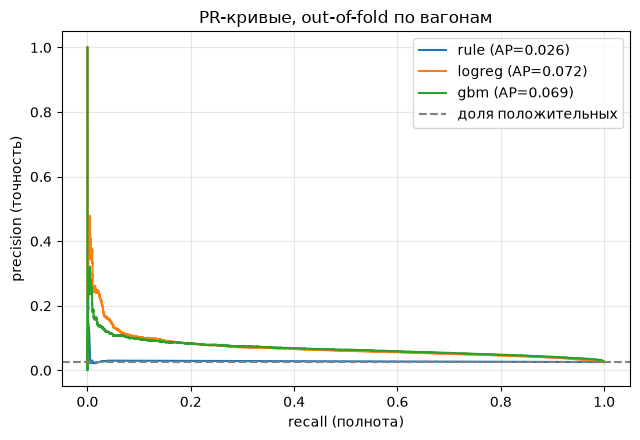

In [12]:
res = []
for name, s in oof.items():
    per_w = [average_precision_score(y[groups == w], s[groups == w]) for w in np.unique(groups)]
    res.append(dict(model=name, pr_auc=average_precision_score(y, s), pr_auc_wagon_mean=np.mean(per_w),
                    roc_auc=roc_auc_score(y, s), recall_at_p30=recall_at_precision(y, s, .3),
                    recall_at_p20=recall_at_precision(y, s, .2), recall_at_p50=recall_at_precision(y, s, .5),
                    lift=average_precision_score(y, s) / y.mean(), prevalence=y.mean()))
res = pd.DataFrame(res).set_index("model").round(4)
display(res)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, s in oof.items():
    p, r, _ = precision_recall_curve(y, s)
    ax.plot(r, p, label=f"{name} (AP={average_precision_score(y, s):.3f})")
ax.axhline(y.mean(), ls="--", c="gray", label="доля положительных")
ax.set_xlabel("recall (полнота)"); ax.set_ylabel("precision (точность)"); ax.set_title("PR-кривые, out-of-fold по вагонам")
ax.legend(); plt.tight_layout(); plt.show()

### 5.1 Важность признаков (permutation, падение PR-AUC на отложенном вагоне)

,mean,std_over_wagons
obj_Vehicle,0.0091,0.0091
speed,0.0039,0.0050
since_danger,0.0037,0.0052
loc_converged,0.0034,0.0016
is_safety_pedal_turned_on_fb,0.0032,0.0031
adas_on,0.0025,0.0019
n_danger_10min,0.0019,0.0061
speed_mean_15s,0.0017,0.0025
since_ctrl_switch,0.0016,0.0033
dist_to_stop,0.0016,0.0035


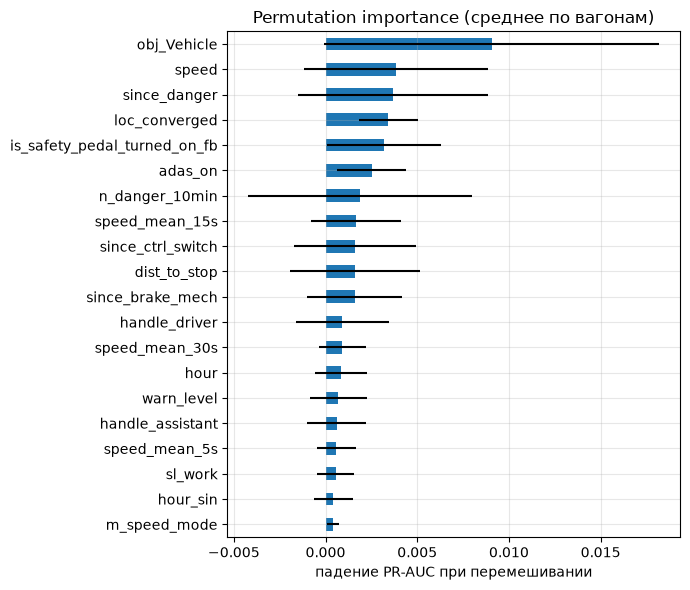

In [13]:
from sklearn.inspection import permutation_importance
rng = np.random.RandomState(SEED)
n_sub = 10000 if FAST else 25000
imps = []
for w, (gb, te) in models.items():
    te_s = te if len(te) <= n_sub else rng.choice(te, n_sub, replace=False)
    if y[te_s].sum() < 20:
        continue
    pi = permutation_importance(gb, X[te_s], y[te_s], scoring="average_precision",
                                n_repeats=2, random_state=SEED, n_jobs=1)
    imps.append(pd.Series(pi.importances_mean, index=FEATS, name=w))
imp = pd.concat(imps, axis=1)
imp["mean"] = imp.mean(1); imp["std_over_wagons"] = imp.drop(columns="mean").std(1)
imp = imp.sort_values("mean", ascending=False)
display(imp[["mean", "std_over_wagons"]].head(20).round(4))
ax = imp["mean"].head(20)[::-1].plot.barh(figsize=(7, 6), xerr=imp["std_over_wagons"].head(20)[::-1])
ax.set_xlabel("падение PR-AUC при перемешивании"); ax.set_title("Permutation importance (среднее по вагонам)")
plt.tight_layout(); plt.show()

### 5.2 Разбор ошибок
Порог модели выбираем так, чтобы точность была не ниже 0.3 (out-of-fold); если такой точности нет, берём 1% самых высоких оценок. Смотрим, где модель пропускает
торможения (FN) и где тревожит зря (FP).

In [14]:
s = oof["gbm"]
p, r, th = precision_recall_curve(y, s)
ok = np.where(p[:-1] >= .3)[0]
thr = th[ok[0]] if len(ok) else np.quantile(s, .99)
pred = s >= thr
D["score"] = s; D["pred"] = pred
D["err"] = np.select([pred & (y == 1), pred & (y == 0), ~pred & (y == 1)], ["TP", "FP", "FN"], "TN")
print(f"порог {thr:.3f}: precision={(y[pred]).mean():.3f}, recall={pred[y==1].mean():.3f}, тревог: {pred.sum():,}")
cols = ["speed", "overspeed", "warn_level", "since_danger", "n_danger_10min", "ctrl_auto", "dist_to_stop", "accel_min_15s"]
display(D.groupby("err")[cols].median().round(2))
D["obj"] = np.select(
    [D.obj_Ped == 1, D.obj_Vehicle == 1, D.obj_Tram == 1, D.obj_TrafficLightSignal == 1, D.obj_na == 1],
    ["Ped", "Vehicle", "Tram", "TL", "NaN"], "Unknown")
pos = D[D.y == 1]
print("Полнота по типу объекта в момент прогноза:"); display(pos.groupby("obj").pred.agg(["size", "mean"]).round(3))
print("Полнота по управлению:"); display(pos.groupby("controller", observed=True).pred.agg(["size", "mean"]).round(3))
print("Полнота по времени до торможения (с):")
display(pos.groupby(pd.cut(pos.tt_next_danger, [0, 2, 5, 7.5, 10]), observed=True).pred.agg(["size", "mean"]).round(3))
print("Доля FN без какого-либо предупреждения (warn_level==0 и объект не Ped/Vehicle):",
      round(((D.err == "FN") & (D.warn_level.fillna(0) == 0) & (D.obj_Ped + D.obj_Vehicle == 0)).sum() / max((D.err == "FN").sum(), 1), 3))
fp = D[D.err == "FP"]
print("FP: сколько из них с торможением по препятствию в пределах 10-30 с (почти попадание):",
      round((fp.tt_next_danger <= 30).mean(), 3))

порог 0.508: precision=0.301, recall=0.005, тревог: 93


,speed,overspeed,warn_level,since_danger,n_danger_10min,ctrl_auto,dist_to_stop,accel_min_15s
err,,,,,,,,
FN,15.12,-19.200001,0.0,177.0,2.0,0.0,44.0,-0.05
FP,0.00,0.000000,242.0,18.0,9.0,0.0,42.0,0.00
TN,4.59,-20.709999,0.0,500.0,1.0,0.0,27.0,0.00
TP,0.00,0.000000,240.5,20.5,5.5,0.0,81.0,0.00


Полнота по типу объекта в момент прогноза:


,size,mean
obj,,
NaN,2215,0.000
Ped,7,0.000
TL,59,0.000
Tram,5,0.000
Unknown,2816,0.000
Vehicle,128,0.219


Полнота по управлению:


,size,mean
controller,,
auto,855,0.000
driver,3857,0.001
und,518,0.048


Полнота по времени до торможения (с):


,size,mean
tt_next_danger,,
"(0.0, 2.0]",1107,0.006
"(2.0, 5.0]",1584,0.005
"(5.0, 7.5]",1046,0.007
"(7.5, 10.0]",1493,0.004


Доля FN без какого-либо предупреждения (warn_level==0 и объект не Ped/Vehicle): 0.959
FP: сколько из них с торможением по препятствию в пределах 10-30 с (почти попадание): 0.338


ERRORS_PLACEHOLDER

## 6. Feature engineering, уровень 2: признаки эпизода и кластеризация

In [15]:
E = eps.copy()
E["duration_s"] = (E["end"] - E["start"]).dt.total_seconds()
E["speed_drop"] = (E["speed_start"] - E["speed_min"]).clip(lower=0)
E["speed_drop_rel"] = E["speed_drop"] / E["speed_start"].clip(lower=1)
E["has_warn"] = (E["warn_max"].fillna(0) > 0).astype(int)
E["reaction_known"] = E["reaction_s"].notna().astype(int)
E["reaction_s_f"] = E["reaction_s"].fillna(0).clip(0, 30)
E["stopped_i"] = E["stopped"].astype(int)
E["ctrl_auto"] = (E["controller"] == "auto").astype(int)
E["n_kinds"] = E["kinds"].apply(len)
E["n_hard"] = E["hard_brakes"].apply(lambda v: len(v) if isinstance(v, list) else 0)
E["skid_i"] = E["skid"].astype(int)
E["obj_ped_veh"] = E["obj_type"].isin(["Ped", "Vehicle"]).astype(int)
E["max_decel"] = E["max_decel"].clip(0, 5)
E["speed_start"] = E["speed_start"].clip(0, MAX_SPEED)
EP_TABLE = pd.DataFrame([
 ("duration_s", "end - start", "длительность воздействия, с", "start, end"),
 ("speed_start, speed_min, speed_end", "скорость в начале/минимум/в конце", "с какой скорости и до какой тормозили, км/ч", "speed"),
 ("speed_drop, speed_drop_rel", "speed_start - speed_min, / speed_start", "абсолютное и относительное падение скорости", "speed"),
 ("max_decel", "max(-dv/dt), обрезан 0..5", "пиковое замедление, м/с²", "speed, t"),
 ("warn_max, has_warn", "max(m_warn_level), >0", "было ли предупреждение водителю", "m_warn_level"),
 ("reaction_s_f, reaction_known", "запрос/предупреждение -> применение, с", "время реакции системы", "*_act, *_real, m_warn_level"),
 ("stopped_i", "speed_end < 1", "закончилось остановкой", "speed"),
 ("ctrl_auto", "controller == auto", "в эпизоде управлял ассистент", "controller"),
 ("n_kinds", "число подсистем в эпизоде", "сложность ситуации (несколько причин)", "danger/tl/sl_real"),
 ("n_hard, skid_i", "число экстренных тормозов, юз", "тяжёлые последствия", "brake_rail/crash/emergency, as_is_skid"),
 ("obj_ped_veh", "obj_type in {Ped, Vehicle}", "уязвимый участник впереди", "goal_obj_type"),
 ("hour", "час начала", "время суток", "t"),
], columns=["признак", "формула", "смысл", "поле-источник"]); EP_TABLE.insert(0, "уровень", "эпизод")
display(EP_TABLE)
CL_FEATS = ["duration_s", "speed_start", "speed_drop_rel", "max_decel", "has_warn", "reaction_s_f", "stopped_i",
            "ctrl_auto", "n_kinds", "n_hard", "skid_i"]
display(E[CL_FEATS + ["severity"]].describe().T.round(2))

,уровень,признак,формула,смысл,поле-источник
0,эпизод,duration_s,end - start,"длительность воздействия, с","start, end"
1,эпизод,"speed_start, speed_min, speed_end",скорость в начале/минимум/в конце,"с какой скорости и до какой тормозили, км/ч",speed
2,эпизод,"speed_drop, speed_drop_rel","speed_start - speed_min, / speed_start",абсолютное и относительное падение скорости,speed
3,эпизод,max_decel,"max(-dv/dt), обрезан 0..5","пиковое замедление, м/с²","speed, t"
4,эпизод,"warn_max, has_warn","max(m_warn_level), >0",было ли предупреждение водителю,m_warn_level
5,эпизод,"reaction_s_f, reaction_known","запрос/предупреждение -> применение, с",время реакции системы,"*_act, *_real, m_warn_level"
6,эпизод,stopped_i,speed_end < 1,закончилось остановкой,speed
7,эпизод,ctrl_auto,controller == auto,в эпизоде управлял ассистент,controller
8,эпизод,n_kinds,число подсистем в эпизоде,сложность ситуации (несколько причин),danger/tl/sl_real
9,эпизод,"n_hard, skid_i","число экстренных тормозов, юз",тяжёлые последствия,"brake_rail/crash/emergency, as_is_skid"


,count,mean,std,min,25%,50%,75%,max
duration_s,13357.0,6.79,10.10,0.0,1.00,3.00,9.00,422.0
speed_start,13357.0,19.94,12.89,0.0,9.80,17.00,29.90,63.7
speed_drop_rel,13357.0,0.49,0.42,0.0,0.04,0.40,1.00,1.0
max_decel,13357.0,0.48,0.44,-0.0,0.18,0.41,0.69,5.0
has_warn,13357.0,0.21,0.41,0.0,0.00,0.00,0.00,1.0
reaction_s_f,13357.0,0.08,0.97,0.0,0.00,0.00,0.00,15.0
stopped_i,13357.0,0.37,0.48,0.0,0.00,0.00,1.00,1.0
ctrl_auto,13357.0,0.53,0.50,0.0,0.00,1.00,1.00,1.0
n_kinds,13357.0,1.07,0.28,1.0,1.00,1.00,1.00,4.0
n_hard,13357.0,0.04,0.20,0.0,0.00,0.00,0.00,3.0


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
Z = E[CL_FEATS].astype(float).copy()
Z["duration_s"] = np.log1p(Z["duration_s"].clip(0, 600)); Z["n_hard"] = np.log1p(Z["n_hard"])
Zs = StandardScaler().fit_transform(Z)
sub = np.random.RandomState(SEED).choice(len(Zs), min(4000, len(Zs)), replace=False)
sil = {}
for k in ([4, 5, 6] if FAST else range(3, 9)):
    lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(Zs)
    sil[k] = silhouette_score(Zs[sub], lab[sub])
print("silhouette:", {k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get) if max(sil.values()) - sil.get(5, 0) > 0.03 else 5
km = KMeans(K, n_init=20, random_state=SEED).fit(Zs)
E["cluster"] = km.labels_
prof = E.groupby("cluster")[CL_FEATS + ["speed_start", "speed_drop", "severity"]].mean().T
prof = prof.loc[~prof.index.duplicated()]
prof.loc["size"] = E.cluster.value_counts().sort_index()
display(prof.round(2))
display(pd.crosstab(E.cluster, E.kind, normalize="index").round(2))

silhouette: {3: 0.142, 4: 0.275, 5: 0.271, 6: 0.28, 7: 0.207, 8: 0.228}


cluster,0,1,2,3,4
duration_s,2.48,7.08,6.77,3.87,5.91
speed_start,13.22,18.89,22.56,17.33,20.69
speed_drop_rel,0.58,0.22,0.97,0.38,0.54
max_decel,0.64,0.30,0.80,0.54,0.57
has_warn,0.22,0.12,0.37,0.23,0.17
reaction_s_f,0.00,0.01,0.02,0.00,12.86
stopped_i,0.72,0.06,0.90,0.46,0.39
ctrl_auto,0.16,0.62,0.39,0.20,0.77
n_kinds,1.50,1.03,1.11,1.30,1.07
n_hard,1.05,0.00,0.00,0.14,0.01


kind,danger,hard_brake,skid,speed_limit,traffic_light
cluster,,,,,
0,0.12,0.74,0.00,0.00,0.14
1,0.23,0.00,0.00,0.64,0.13
2,0.26,0.00,0.00,0.42,0.32
3,0.05,0.08,0.65,0.10,0.11
4,0.10,0.01,0.00,0.77,0.11


,имя,эпизодов,тип (чаще всего),средняя тяжесть,v_старт,max_decel,"длит., с"
0,"экстренное торможение/юз, до остановки, водите...",454,hard_brake,2.76,13.2,0.64,2.5
1,"без остановки, мягкое (сброс < 30%)",8211,speed_limit,0.58,18.9,0.30,7.1
2,"до остановки, сброс скорости почти до нуля",4512,speed_limit,0.84,22.6,0.80,6.8
3,"экстренное торможение/юз, водитель",110,skid,2.08,17.3,0.54,3.9
4,"ассистент, запоздалое применение (реакция 13 с)",70,speed_limit,0.34,20.7,0.57,5.9


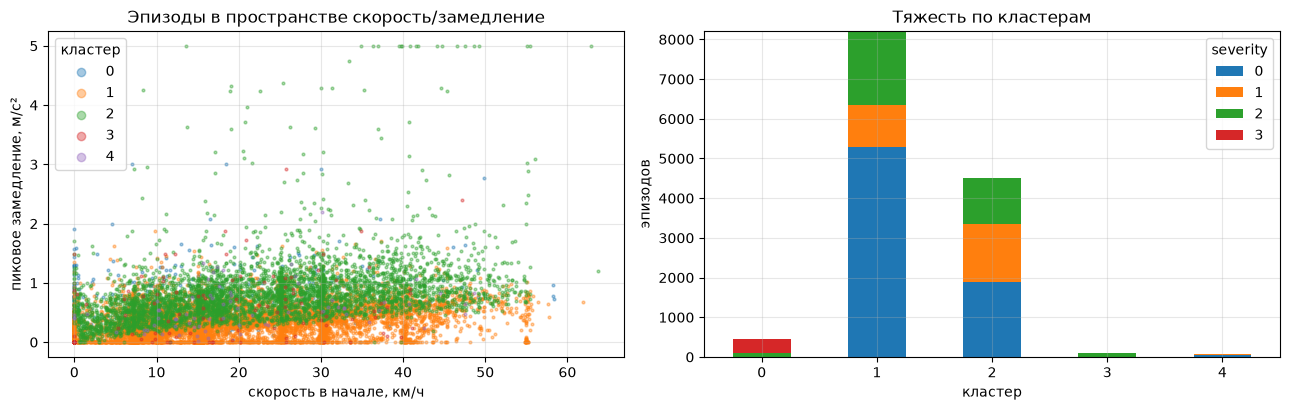

In [17]:
def name_cluster(r):
    tags = []
    if r.n_hard >= .5 or r.skid_i > .3: tags.append("экстренное торможение/юз")
    if r.max_decel >= 1.5: tags.append("резкое замедление")
    if r.n_kinds >= 1.5: tags.append("несколько подсистем")
    if r.stopped_i > .7: tags.append("до остановки")
    elif r.stopped_i < .3: tags.append("без остановки")
    if r.ctrl_auto > .7: tags.append("ассистент")
    elif r.ctrl_auto < .3: tags.append("водитель")
    if r.has_warn > .5: tags.append("с предупреждением")
    if r.speed_start < 10: tags.append("на малой скорости")
    elif r.speed_start > 25: tags.append("на высокой скорости")
    if r.reaction_s_f > 3: tags.append(f"запоздалое применение (реакция {r.reaction_s_f:.0f} с)")
    if r.speed_drop_rel > .8: tags.append("сброс скорости почти до нуля")
    elif r.speed_drop_rel < .3: tags.append("мягкое (сброс < 30%)")
    if r.duration_s > 20: tags.append("долгое")
    elif r.duration_s < 3: tags.append("короткое")
    return ", ".join(tags) or "типичное"
names = {c: name_cluster(prof[c]) for c in prof.columns}
summary = pd.DataFrame({"имя": names, "эпизодов": prof.loc["size"].astype(int),
                        "тип (чаще всего)": pd.crosstab(E.cluster, E.kind).idxmax(1),
                        "средняя тяжесть": prof.loc["severity"].round(2),
                        "v_старт": prof.loc["speed_start"].round(1), "max_decel": prof.loc["max_decel"].round(2),
                        "длит., с": prof.loc["duration_s"].round(1)})
E["cluster_name"] = E["cluster"].map(names)
display(summary)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for c in sorted(E.cluster.unique()):
    m = E.cluster == c
    ax[0].scatter(E.speed_start[m], E.max_decel[m], s=4, alpha=.4, label=f"{c}")
ax[0].set_xlabel("скорость в начале, км/ч"); ax[0].set_ylabel("пиковое замедление, м/с²"); ax[0].legend(title="кластер", markerscale=3)
ax[0].set_title("Эпизоды в пространстве скорость/замедление")
pd.crosstab(E.cluster, E.severity).plot.bar(stacked=True, ax=ax[1], rot=0)
ax[1].set_title("Тяжесть по кластерам"); ax[1].set_ylabel("эпизодов"); ax[1].set_xlabel("кластер")
plt.tight_layout(); plt.show()

CLUSTER_INTERPRETATION_PLACEHOLDER

## 7. Сохранение признаков для дашборда

In [18]:
del X; gc.collect()
del models; gc.collect()
row_out = pd.read_parquet(OUT / "row_features.parquet")   # признаки сохранены в разделе 4, добавляем оценку модели
row_out["score_danger_10s"] = np.float32(np.nan)
row_out.loc[mask, "score_danger_10s"] = D["score"].values.astype("float32")
row_out.to_parquet(OUT / "row_features.parquet", index=False); del row_out; gc.collect()
ep_cols = ["id", "trip", "wagon", "kind", "start", "end", "route", "stop", "lat", "lon", "obj_type", "controller",
           "severity", "hour", "speed_end", "speed_drop", "warn_max", "reaction_s"] + CL_FEATS + ["obj_ped_veh", "cluster", "cluster_name"]
E[list(dict.fromkeys(ep_cols))].to_parquet(OUT / "episode_features.parquet", index=False)
pd.concat([feat_table_rows, EP_TABLE]).to_csv(OUT / "feature_table.csv", index=False, encoding="utf-8-sig")
imp[["mean", "std_over_wagons"]].rename_axis("feature").to_csv(OUT / "feature_importance.csv")
json.dump({"task": f"danger_real onset within {HORIZON_S}s", "split": "leave-one-wagon-out",
           "metrics": res.reset_index().to_dict("records"), "threshold": float(thr),
           "clusters": summary.reset_index().rename(columns={"index": "cluster"}).astype(str).to_dict("records")},
          open(OUT / "metrics.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
for f in sorted(OUT.iterdir()):
    print(f"{f.name:28s} {f.stat().st_size/2**20:7.2f} МБ")

episode_features.parquet        0.71 МБ
feature_importance.csv          0.00 МБ
feature_table.csv               0.01 МБ
metrics.json                    0.00 МБ
row_features.parquet           16.89 МБ
